In [23]:
import os
import tarfile
import urllib.request
import pandas as pd
import numpy as np
import re

# URLs et chemins
TAR_URL = "https://www.phase-trans.msm.cam.ac.uk/map/data/tar/welddb.tar"
DATA_DIR = os.path.join("..", "data")
TAR_PATH = os.path.join(DATA_DIR, "welddb.tar")
DATA_PATH = os.path.join(DATA_DIR, "welddb.data")

# 1. Création du dossier et téléchargement si nécessaire
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_PATH):
    req = urllib.request.Request(TAR_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as response, open(TAR_PATH, "wb") as f:
        f.write(response.read())

    # 2. Extraction du fichier welddb.data
    with tarfile.open(TAR_PATH) as tar:
        tar.extract("welddb.data", path=DATA_DIR)

# 3. Chargement dans Pandas (gestion des valeurs manquantes 'N')
df = pd.read_csv(DATA_PATH, sep=r"\s+", na_values=["N"], header=None)

print(f"Dataset chargé avec succès ! Dimensions : {df.shape}")
df.head()

Dataset chargé avec succès ! Dimensions : (1652, 44)


,0,1,2,3,4,5,6,7,8,9,...,34,35,36,37,38,39,40,41,42,43
0,0.037,0.30,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.30,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,...,-28.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.30,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,...,-38.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aht
3,0.037,0.31,1.03,0.007,0.014,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Baw
4,0.037,0.31,1.03,0.007,0.014,0.0,NaN,NaN,NaN,NaN,...,-48.0,100.0,NaN,NaN,32,28.0,40.0,0.0,0.0,Evans-Ni/CMn-1990/1991-0Bawch


In [24]:
# Dictionnaire des 44 noms de colonnes explicites
columns_names = [
    # Composition chimique (col 1:21)
    "C_wt", "Si_wt", "Mn_wt", "S_wt", "P_wt", "Ni_wt", "Cr_wt", "Mo_wt", 
    "V_wt", "Cu_wt", "Co_wt", "W_wt", "O_ppm", "Ti_ppm", "N_ppm", "Al_ppm", 
    "B_ppm", "Nb_ppm", "Sn_ppm", "As_ppm", "Sb_ppm",
    
    # Conditions physiques et procédé de soudage
    "Current_A", "Voltage_V", "AC_DC", "Polarity", "Heat_input", "Interpass_temp", "Weld_type",
    
    # Traitement thermique post-soudage
    "PWHT_temp", "PWHT_time",
    
    # Propriétés mécaniques et cibles
    "Yield_strength", "UTS", "Elongation", "Reduction_area", "Charpy_temp", "Charpy_energy", 
    "Hardness", "FATT_50", "Primary_ferrite", "Ferrite_2nd_phase", "Acicular_ferrite", 
    "Martensite", "Ferrite_carbide", "Weld_ID"
]

df.columns = columns_names
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   C_wt               1652 non-null   float64
 1   Si_wt              1652 non-null   float64
 2   Mn_wt              1652 non-null   float64
 3   S_wt               1648 non-null   str    
 4   P_wt               1642 non-null   float64
 5   Ni_wt              697 non-null    float64
 6   Cr_wt              784 non-null    float64
 7   Mo_wt              793 non-null    str    
 8   V_wt               928 non-null    str    
 9   Cu_wt              578 non-null    str    
 10  Co_wt              129 non-null    str    
 11  W_wt               75 non-null     str    
 12  O_ppm              1256 non-null   float64
 13  Ti_ppm             935 non-null    str    
 14  N_ppm              1242 non-null   str    
 15  Al_ppm             905 non-null    str    
 16  B_ppm              504 non-null    

In [25]:
# Suppression des colonnes très creuses et non utilisées
df = df.drop(columns=["Hardness", "FATT_50"])
df["AC_DC"].value_counts()

AC_DC
DC    1395
AC      42
Name: count, dtype: int64

In [26]:
# Normalisation des types de soudure
df["Weld_type"] = df["Weld_type"].replace("ShMA", "MMA")
df["Weld_type"] = df["Weld_type"].replace("SA", "SMA")

groupe_a_supprimer = ["GMAA", "GTAA", "SAA", "NGGMA", "NGSAW"]
df = df[~df["Weld_type"].isin(groupe_a_supprimer)]

df["Weld_type"].value_counts()

Weld_type
MMA    1180
SMA     261
FCA      87
TSA      87
Name: count, dtype: int64

In [27]:
# Point 4 : Prétraitement spécifique des valeurs manquantes de composition
def traiter_valeur(val):
    val_str = str(val).strip()
    if val_str.startswith("<"):
        return float(val_str.replace("<", "")) / 2
    try:
        return float(val)
    except ValueError:
        return val

colonne_a_traiter = df.columns[1:21]
df[colonne_a_traiter] = df[colonne_a_traiter].map(traiter_valeur)

# Remplissage par 0 UNIQUEMENT pour les éléments d'alliage (non reporté = non ajouté)
elements_alliage = ["Ni_wt", "Cr_wt", "Mo_wt", "V_wt", "Cu_wt", "Co_wt", "W_wt",
                    "B_ppm", "Nb_ppm", "Sn_ppm", "As_ppm", "Sb_ppm"]

df[elements_alliage] = df[elements_alliage].fillna(0)

# O_ppm, N_ppm, Ti_ppm, Al_ppm restent NaN -> ils seront imputés par la médiane avec indicateur dans le pipeline
df["Interpass_temp"] = pd.to_numeric(df["Interpass_temp"].replace("150-200", 175))

df['N_ppm_temp'] = df['N_ppm'].astype(str).str.extract(r'^(\d+)')
df['N_ppm'] = pd.to_numeric(df['N_ppm_temp'], errors='coerce')
df = df.drop(columns=['N_ppm_temp'])

# Détection des essais Charpy à énergie vs température fixée
cond_valeurs_fixes = df["Charpy_energy"].isin([28, 50, 100])
cond_autres_floats = df["Charpy_energy"].notna() & ~cond_valeurs_fixes

df["Charpy_energy_fixed"] = np.select([cond_valeurs_fixes, cond_autres_floats], [1, 0], default=np.nan)

On conserve uniquement les 4 procédés principaux de soudure : MMA (soudure à l'arc à la main), SMA (arc submergé), FCA (fil fourré) et TSA (arc submergé tandem). Chaque type fera l'objet d'une sous-analyse, l'étude principale se concentrant sur les soudures MMA.

In [28]:
df_mma = df[df["Weld_type"] == "MMA"].copy()
df_sma = df[df["Weld_type"] == "SMA"].copy()
df_fca = df[df["Weld_type"] == "FCA"].copy()
df_tsa = df[df["Weld_type"] == "TSA"].copy()

df_mma.to_csv("mma_dataset.csv", index=False)
df_sma.to_csv("sma_dataset.csv", index=False)
df_fca.to_csv("fca_dataset.csv", index=False)
df_tsa.to_csv("tsa_dataset.csv", index=False)

print(f"Nombre de soudures MMA retenues : {len(df_mma)}")

Nombre de soudures MMA retenues : 1180


# Étude des soudures MMA (Manuel Metal Arc)

## 1. Définition des Critères de Conformité (Labels) et Distribution des Variables Cibles

Pour évaluer la qualité d'une soudure, nous définissons deux modèles complémentaires :
1. **Model Traction (Résistance mécanique)** :
   - Yield_Strength $\ge 380\text{ MPa}$
   - UTS $\ge 475\text{ MPa}$
   - Elongation $\ge 18\%$
   - Rapport $\text{Yield}/\text{UTS} \le 0.90$ (aligné avec les exigences des normes de structure)

2. **Model Ductilité (Résilience Charpy - Point 3)** :
   - Pour essai à énergie fixée : Température de transition $T < -20^\circ\text{C}$.
   - Pour essai à température fixée : Énergie absorbée $E > 27\text{ J}$ mesurée à $T \le -20^\circ\text{C}$.
   - Non informatif (label -1) : $E > 27\text{ J}$ à $T > -20^\circ\text{C}$ ou $E \le 27\text{ J}$ à $T < -20^\circ\text{C}$. Ces lignes rejoignent le pool non labellisé pour le Self-Training.

In [29]:
# Distribution des propriétés mécaniques cibles (Quantiles 5%, 50%, 95%)
df_mma[['Yield_strength', 'UTS', 'Elongation']].describe(percentiles=[0.05, 0.5, 0.95])

,Yield_strength,UTS,Elongation
count,526.000000,510.000000,489.000000
mean,498.477947,583.444118,26.625153
std,83.031611,84.313552,4.742954
min,329.000000,447.000000,10.600000
5%,387.500000,476.900000,18.000000
50%,486.400000,568.000000,27.400000
95%,647.500000,737.000000,33.300000
max,920.000000,1151.000000,36.400000


In [30]:
# --- Point 3 : Label Traction ---
cond_traction = (
    (df_mma["Yield_strength"] >= 380) &
    (df_mma["UTS"] >= 475) &
    (df_mma["Elongation"] >= 18) &
    ((df_mma["Yield_strength"] / df_mma["UTS"]) <= 0.90)
)
has_traction = df_mma["Yield_strength"].notna() & df_mma["UTS"].notna() & df_mma["Elongation"].notna()
df_mma["Valid_Traction"] = np.where(has_traction, np.where(cond_traction, 1, 0), -1)

# --- Point 3 : Label Charpy / Ductilité ---
fixed_E = df_mma["Charpy_energy_fixed"] == 1
fixed_T = df_mma["Charpy_energy_fixed"] == 0
T, E = df_mma["Charpy_temp"], df_mma["Charpy_energy"]

good = (fixed_E & (T < -20)) | (fixed_T & (E > 27) & (T <= -20))
bad = (fixed_E & (E == 28) & (T > -20)) | (fixed_T & (E <= 27) & (T >= -20))

df_mma["Valid_Ductile"] = np.select([good, bad], [1, 0], default=-1 )

# --- Point 2 : Définition d'un ensemble de Features X unique et cohérent ---
non_features = [
    "Weld_type", "Weld_ID", "Valid_Traction", "Valid_Ductile",
    "Charpy_temp", "Charpy_energy", "Charpy_energy_fixed",
    "Yield_strength", "UTS", "Elongation", "Reduction_area",
    "Primary_ferrite", "Ferrite_2nd_phase", "Acicular_ferrite",
    "Martensite", "Ferrite_carbide"
]

X = df_mma.drop(columns=non_features)

print("--- Distribution des labels Valid_Traction ---")
print(df_mma["Valid_Traction"].value_counts())

print("\n--- Distribution des labels Valid_Ductile ---")
print(df_mma["Valid_Ductile"].value_counts())

print(f"\nNombre total de features d'entrée X : {X.shape[1]}")

--- Distribution des labels Valid_Traction ---
Valid_Traction
-1    691
 1    389
 0    100
Name: count, dtype: int64

--- Distribution des labels Valid_Ductile ---
Valid_Ductile
-1    657
 1    512
 0     11
Name: count, dtype: int64

Nombre total de features d'entrée X : 29


## 2. Détection des Soudures Jumelées 

Deux essais ayant exactement la même composition chimique proviennent du même métal d'apport / bain de fusion. Un split aléatoire standard risquerait de placer deux "jumeaux" dans le train et le test, induisant un surapprentissage par mémorisation de la composition.
Nous créons un groupe unique pour chaque composition chimique unique (21 premières colonnes).

In [31]:
# Point 1 : Construction des groupes basés sur la composition chimique
chem_cols = list(df_mma.columns[:21])

# Nettoyage, arrondissement et conversion stricte en chaînes de caractères
chem_str = df_mma[chem_cols].round(4).fillna("missing").astype(str)
combined = chem_str.apply(lambda row: "|".join(row), axis=1)

groups = pd.Series(pd.factorize(combined)[0], index=df_mma.index)

print(f"Nombre de soudures MMA : {len(df_mma)}")
print(f"Nombre de compositions uniques (groupes) : {groups.nunique()}")

Nombre de soudures MMA : 1180
Nombre de compositions uniques (groupes) : 411


## 3. Protocole d'Évaluation Rigoureux (Points 4 & 5a)

1. **Jeu de test réservé unique** : Créé en une seule fois via `GroupShuffleSplit` sur l'ensemble des données labellisées (Traction ou Charpy). Aucun échantillon du jeu de test n'est vu lors des étapes d'entraînement ou de réglage des hyperparamètres.
2. **Prétraitement adapté (Point 4)** :
   - Éléments d'alliage non reportés : remplis par 0 lors du nettoyage.
   - Gaz résiduels ($O$, $N$, $Ti$, $Al$) : imputés par la médiane avec `add_indicator=True` pour signaler leur absence initiale au modèle.
   - Interpass_temp et variables catégorielles : gérées de manière robuste via `FunctionTransformer(convert_to_string)`.

In [32]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA

# --- Point 5a : Split Réservé Groupé ---
lab_any = (df_mma["Valid_Traction"] != -1) | (df_mma["Valid_Ductile"] != -1)
idx_labeled_any = df_mma.index[lab_any]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_dev, te_test = next(gss.split(idx_labeled_any, groups=groups.loc[idx_labeled_any]))

idx_test = idx_labeled_any[te_test]
df_dev = df_mma.drop(index=idx_test)

X_dev = df_dev.drop(columns=non_features)
groups_dev = groups.loc[df_dev.index]

X_test = df_mma.loc[idx_test].drop(columns=non_features)
groups_test = groups.loc[idx_test]

print(f"Taille du pool de développement (df_dev) : {len(df_dev)} (inclut le pool non labellisé)")
print(f"Taille du jeu de test réservé (df_test) : {len(idx_test)}")

# --- Point 4 : Preprocessor unique avec SimpleImputer(strategy='median', add_indicator=True) ---
def convert_to_string(df_cat):
    return df_cat.astype(str)

cat_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler()),
])

cat_transformer = Pipeline([
    ('to_string', FunctionTransformer(convert_to_string, feature_names_out='one-to-one')),
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

Taille du pool de développement (df_dev) : 974 (inclut le pool non labellisé)
Taille du jeu de test réservé (df_test) : 206


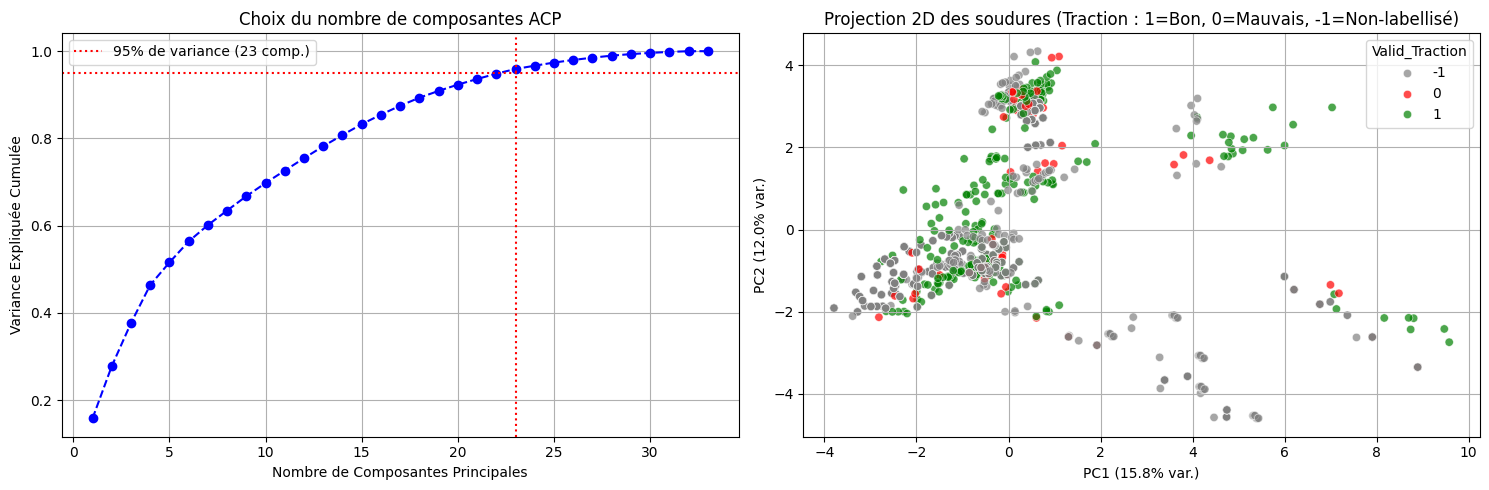

Nombre de composantes nécessaires pour conserver 95% de la variance : 23 sur 27


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Extrait et transforme directement les données numériques via num_transformer
X_num_prep = num_transformer.fit_transform(X_dev[num_cols])

# 2. Calcul de l'ACP complète pour analyser la variance
pca_full = PCA().fit(X_num_prep)
var_cum = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = np.argmax(var_cum >= 0.95) + 1

# --- Graphique 1 : Éboulis des valeurs propres (Variance expliquée cumulée) ---
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(range(1, len(var_cum) + 1), var_cum, marker='o', linestyle='--', color='b')
ax[0].axhline(y=0.95, color='r', linestyle=':', label=f'95% de variance ({n_95} comp.)')
ax[0].axvline(x=n_95, color='r', linestyle=':')
ax[0].set_xlabel('Nombre de Composantes Principales')
ax[0].set_ylabel('Variance Expliquée Cumulée')
ax[0].set_title('Choix du nombre de composantes ACP')
ax[0].legend()
ax[0].grid(True)

# --- Graphique 2 : Projection 2D (PC1 vs PC2) selon la qualité Traction ---
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_num_prep)

y_tr_dev = df_dev.loc[X_dev.index, "Valid_Traction"]

sns.scatterplot(
    x=X_pca_2d[:, 0], y=X_pca_2d[:, 1],
    hue=y_tr_dev,
    palette={1: "green", 0: "red", -1: "gray"},
    alpha=0.7, ax=ax[1]
)
ax[1].set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}% var.)')
ax[1].set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}% var.)')
ax[1].set_title('Projection 2D des soudures (Traction : 1=Bon, 0=Mauvais, -1=Non-labellisé)')
ax[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Nombre de composantes nécessaires pour conserver 95% de la variance : {n_95} sur {len(num_cols)}")

## 4. Évaluation par Cross-Validation (Points 1, 5b & 7)

Nous définissons la fonction `oof_probas` qui réalise la validation croisée *Out-Of-Fold* pour :
1. Le modèle **Supervisé baseline** (RandomForest).
2. Le modèle **Semi-supervisé** (Self-Training Classifier).

Cette fonction permet la comparaison directe entre une CV groupée (`StratifiedGroupKFold`) et une CV non groupée (`StratifiedKFold`) pour mesurer l'impact de la mémorisation de la composition (Point 1).

In [34]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import precision_score, recall_score, balanced_accuracy_score, average_precision_score, roc_auc_score
from sklearn.decomposition import PCA

# --- Point 5b : oof_probas ---
def oof_probas(
    X,
    y_semi,
    groups,
    preprocessor,
    base_clf,
    thr_self=0.80,
    cv_splitter=None,
    seed=42,
):
    lab = (y_semi != -1).values
    Xl = X.iloc[lab]
    yl = y_semi.iloc[lab]
    gl = groups.iloc[lab]

    Xu = X.iloc[~lab]
    yu = y_semi.iloc[~lab]

    p_sup = pd.Series(np.nan, index=Xl.index)
    p_semi = p_sup.copy()

    if cv_splitter is None:
        cv_splitter = StratifiedGroupKFold(
            n_splits=5, shuffle=True, random_state=seed
        )
        splits = list(cv_splitter.split(Xl, yl, gl))
    else:
        splits = list(cv_splitter.split(Xl, yl))

    for tr_idx, te_idx in splits:
        # 1. Pipeline Supervisée baseline
        sup = Pipeline(
            [("prep", clone(preprocessor)), ("clf", clone(base_clf))]
        )
        sup.fit(Xl.iloc[tr_idx], yl.iloc[tr_idx])
        p_sup.iloc[te_idx] = sup.predict_proba(Xl.iloc[te_idx])[:, 1]

        # 2. Pipeline Semi-Supervisée (Self-Training)
        semi = Pipeline(
            [
                ("prep", clone(preprocessor)),
                (
                    "clf",
                    SelfTrainingClassifier(
                        clone(base_clf), threshold=thr_self
                    ),
                ),
            ]
        )
        X_tr_concat = pd.concat([Xl.iloc[tr_idx], Xu])
        y_tr_concat = pd.concat([yl.iloc[tr_idx], yu])
        semi.fit(X_tr_concat, y_tr_concat)
        p_semi.iloc[te_idx] = semi.predict_proba(Xl.iloc[te_idx])[:, 1]

    return yl, p_sup, p_semi

# --- Point 7 : Métriques orientées sécurité ---
def report(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {
        "rec_0": recall_score(y, pred, pos_label=0, zero_division=0),
        "prec_1": precision_score(y, pred, pos_label=1, zero_division=0),
        "bal_acc": balanced_accuracy_score(y, pred),
        "pr_auc_0": average_precision_score(1 - y, 1 - p),
        "roc_auc": roc_auc_score(y, p),
    }

In [35]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC

# Dictionnaire des algorithmes à comparer
dict_modeles = {
    "Random Forest": RandomForestClassifier( n_estimators=100, random_state=42, class_weight="balanced"),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "SVM (RBF)": CalibratedClassifierCV(SVC(class_weight="balanced", random_state=42), ensemble=False),
}

base_rf = dict_modeles["Random Forest"]

# --- 1. MODÈLE TRACTION ---
res_tr_sup, res_tr_semi = {}, {}

for nom, clf in dict_modeles.items():
    yl_tr, p_sup, p_semi = oof_probas(
        X_dev,
        df_dev["Valid_Traction"],
        groups_dev,
        preprocessor,
        clf,
        thr_self=0.80,
    )
    res_tr_sup[nom] = report(yl_tr, p_sup)
    res_tr_semi[nom] = report(yl_tr, p_semi)

# Sauvegarde des probabilités de Random Forest pour le calibrage de seuil ultérieur
_, p_sup_ng, _ = oof_probas(X_dev, df_dev["Valid_Traction"], groups_dev, preprocessor,
                            dict_modeles["Random Forest"],
                            cv_splitter=StratifiedKFold(5, shuffle=True, random_state=42))

print("=== 1. MODÈLE TRACTION : SUPERVISÉ PUR (GROUPED CV) ===")
display(pd.DataFrame(res_tr_sup).round(3))

print("\n=== 1. MODÈLE TRACTION : SEMI-SUPERVISÉ (GROUPED CV) ===")
display(pd.DataFrame(res_tr_semi).round(3))


# --- 2. MODÈLE DUCTILITÉ (CHARPY) ---
res_du_sup, res_du_semi = {}, {}

for nom, clf in dict_modeles.items():
    yl_du, p_sup, p_semi = oof_probas(
        X_dev,
        df_dev["Valid_Ductile"],
        groups_dev,
        preprocessor,
        clf,
        thr_self=0.80,
    )
    res_du_sup[nom] = report(yl_du, p_sup)
    res_du_semi[nom] = report(yl_du, p_semi)

# Sauvegarde des probabilités de Random Forest pour le calibrage de seuil ultérieur
_, p_sup_du_grp, p_semi_du_grp = oof_probas(
    X_dev,
    df_dev["Valid_Ductile"],
    groups_dev,
    preprocessor,
    dict_modeles["Random Forest"],
    thr_self=0.80,
)

print("\n=== 2. MODÈLE DUCTILITÉ : SUPERVISÉ PUR (GROUPED CV) ===")
display(pd.DataFrame(res_du_sup).round(3))

print("\n=== 2. MODÈLE DUCTILITÉ : SEMI-SUPERVISÉ (GROUPED CV) ===")
display(pd.DataFrame(res_du_semi).round(3))

=== 1. MODÈLE TRACTION : SUPERVISÉ PUR (GROUPED CV) ===


,Random Forest,Hist Gradient Boosting,Logistic Regression,SVM (RBF)
rec_0,0.444,0.264,0.569,0.000
prec_1,0.875,0.845,0.867,0.811
bal_acc,0.674,0.601,0.612,0.500
pr_auc_0,0.541,0.447,0.378,0.129
roc_auc,0.786,0.730,0.694,0.293



=== 1. MODÈLE TRACTION : SEMI-SUPERVISÉ (GROUPED CV) ===


,Random Forest,Hist Gradient Boosting,Logistic Regression,SVM (RBF)
rec_0,0.375,0.306,0.417,0.000
prec_1,0.863,0.853,0.851,0.811
bal_acc,0.647,0.620,0.595,0.500
pr_auc_0,0.481,0.445,0.357,0.298
roc_auc,0.747,0.730,0.657,0.610



=== 2. MODÈLE DUCTILITÉ : SUPERVISÉ PUR (GROUPED CV) ===


,Random Forest,Hist Gradient Boosting,Logistic Regression,SVM (RBF)
rec_0,1.000,0.900,0.900,0.400
prec_1,1.000,0.997,0.997,0.985
bal_acc,0.999,0.949,0.949,0.700
pr_auc_0,0.818,0.823,0.959,0.911
roc_auc,0.998,0.998,0.999,0.998



=== 2. MODÈLE DUCTILITÉ : SEMI-SUPERVISÉ (GROUPED CV) ===


,Random Forest,Hist Gradient Boosting,Logistic Regression,SVM (RBF)
rec_0,1.000,0.900,0.900,0.500
prec_1,1.000,0.997,0.997,0.987
bal_acc,0.999,0.949,0.949,0.749
pr_auc_0,0.892,0.890,0.981,0.485
roc_auc,0.998,0.998,0.999,0.838


## 5. Calibrage des Seuils de Décision et Évaluation Finale sur Test Réservé 

L'erreur la plus critique dans la qualification d'une soudure est le **faux positif** (accepter une mauvaise soudure). Nous recherchons le seuil optimal sur les probabilités OOF de `df_dev` garantissant un rappel de la classe 0 d'au moins 90% (`rec_0 >= 0.90`). Ce seuil calibré est ensuite appliqué une unique fois sur le jeu de test réservé.

In [36]:
def trouver_seuil_optimal(y, p, target_rec0=0.90):
    for s in np.linspace(0.05, 0.99, 95):
        if report(y, p, thr=s)["rec_0"] >= target_rec0:
            return s
    raise ValueError(f"rec_0 >= {target_rec0} inatteignable (max = {report(y, p, 0.99)['rec_0']:.2f})")

seuil_opt_tr = trouver_seuil_optimal(yl_tr, p_semi_tr_grp, target_rec0=0.90)
seuil_opt_du = trouver_seuil_optimal(yl_du, p_semi_du_grp, target_rec0=0.90)

print(f"Seuil de sécurité optimisé pour Traction : {seuil_opt_tr:.2f}")
print(f"Seuil de sécurité optimisé pour Ductilité : {seuil_opt_du:.2f}")


# Entraînement final des pipelines semi-supervisés sur df_dev
lab_tr = (df_dev["Valid_Traction"] != -1)
model_tr = Pipeline([
    ('prep', clone(preprocessor)),
    ('clf', SelfTrainingClassifier(clone(base_rf), threshold=0.80))
])
model_tr.fit(X_dev, df_dev["Valid_Traction"])

lab_du = (df_dev["Valid_Ductile"] != -1)
model_du = Pipeline([
    ('prep', clone(preprocessor)),
    ('clf', SelfTrainingClassifier(clone(base_rf), threshold=0.80))
])
model_du.fit(X_dev, df_dev["Valid_Ductile"])

# Prédictions sur le jeu de TEST réservé
y_test_tr_true = df_mma.loc[idx_test, "Valid_Traction"]
mask_test_tr = y_test_tr_true != -1
if mask_test_tr.sum() > 0:
    p_test_tr = model_tr.predict_proba(X_test.loc[mask_test_tr])[:, 1]
    print("\n--- ÉVALUATION TEST RÉSERVÉ : TRACTION ---")
    display(pd.Series(report(y_test_tr_true[mask_test_tr], p_test_tr, thr=seuil_opt_tr)))

y_test_du_true = df_mma.loc[idx_test, "Valid_Ductile"]
mask_test_du = y_test_du_true != -1
if mask_test_du.sum() > 0:
    p_test_du = model_du.predict_proba(X_test.loc[mask_test_du])[:, 1]
    print("\n--- ÉVALUATION TEST RÉSERVÉ : DUCTILITÉ ---")
    display(pd.Series(report(y_test_du_true[mask_test_du], p_test_du, thr=seuil_opt_du)))

ValueError: Found input variables with inconsistent numbers of samples: [381, 380]

C:\Users\xavie\AppData\Local\Temp\ipykernel_16940\1961749349.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\xavie\AppData\Local\Temp\ipykernel_16940\1961749349.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


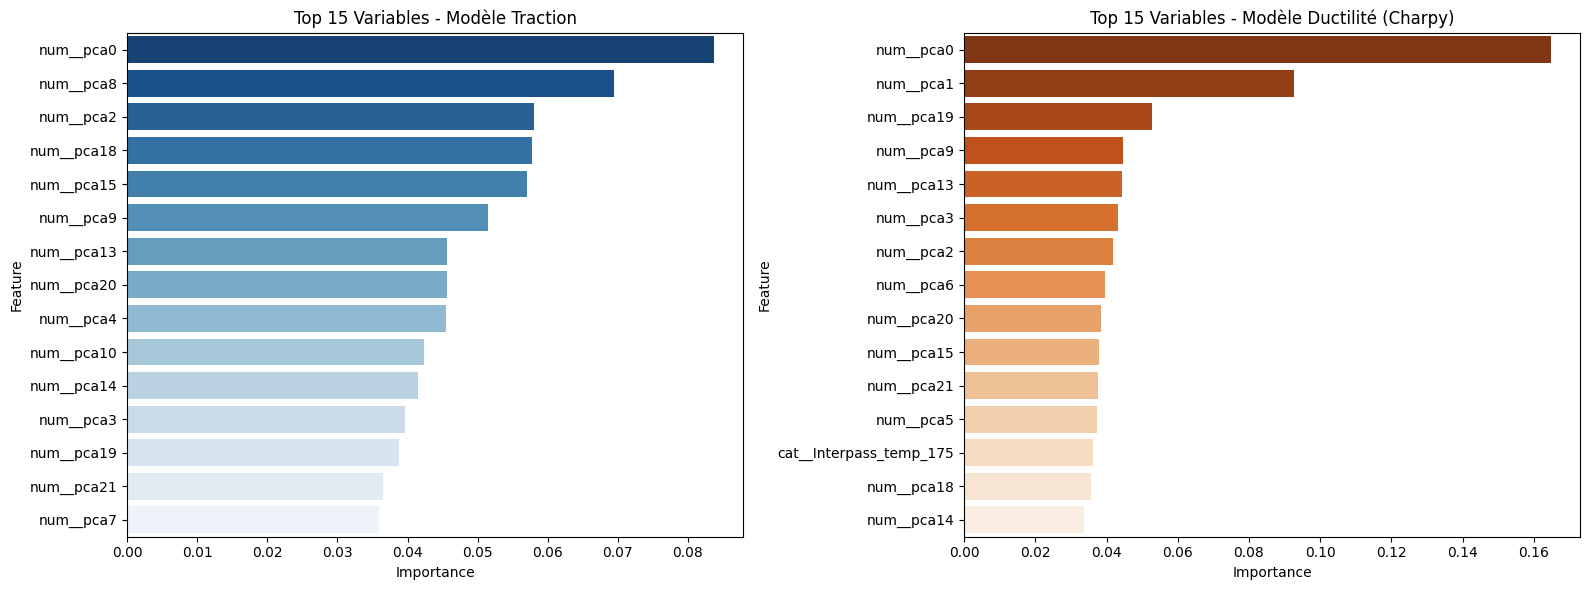

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Extraction des noms de variables générées par le Preprocessor
feature_names = model_tr.named_steps["prep"].get_feature_names_out()

# 2. Extraction du Random Forest entraîné dans le SelfTrainingClassifier
rf_tr = model_tr.named_steps["clf"].estimator_
rf_du = model_du.named_steps["clf"].estimator_

# 3. DataFrame des importances pour la Traction
df_imp_tr = (
    pd.DataFrame(
        {"Feature": feature_names, "Importance": rf_tr.feature_importances_}
    )
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# 4. DataFrame des importances pour la Ductilité (Charpy)
df_imp_du = (
    pd.DataFrame(
        {"Feature": feature_names, "Importance": rf_du.feature_importances_}
    )
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# --- Visualisation des Top 15 ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=df_imp_tr.head(15),
    x="Importance",
    y="Feature",
    ax=axes[0],
    palette="Blues_r",
)
axes[0].set_title("Top 15 Variables - Modèle Traction")

sns.barplot(
    data=df_imp_du.head(15),
    x="Importance",
    y="Feature",
    ax=axes[1],
    palette="Oranges_r",
)
axes[1].set_title("Top 15 Variables - Modèle Ductilité (Charpy)")

plt.tight_layout()
plt.show()

## 6. Décision Combinée de Conformité

Une soudure est validée pour l'usage industriel uniquement si elle satisfait aux exigences de **Traction** ET de **Ductilité** (`OK_Traction & OK_Ductile`).

In [ ]:
# Vérification du nombre d'échantillons du jeu de test possédant les DEUX labels
mask_both = (df_mma.loc[idx_test, "Valid_Traction"] != -1) & (df_mma.loc[idx_test, "Valid_Ductile"] != -1)
n_both = mask_both.sum()

print(f"Nombre d'échantillons du jeu de test avec les deux labels : {n_both}")

def evaluer_nouvelles_soudures(X_new):
    p_tr = model_tr.predict_proba(X_new)[:, 1]
    p_du = model_du.predict_proba(X_new)[:, 1]
    
    ok_tr = p_tr >= seuil_opt_tr
    ok_du = p_du >= seuil_opt_du
    
    return pd.DataFrame({
        "Prob_Traction": p_tr,
        "OK_Traction": ok_tr,
        "Prob_Ductilite": p_du,
        "OK_Ductilite": ok_du,
        "Soudure_Conforme": ok_tr & ok_du
    }, index=X_new.index)

# Exemple de prédiction sur les 5 premières soudures du jeu de test
res_combine = evaluer_nouvelles_soudures(X_test.iloc[:5])
display(res_combine)

Nombre d'échantillons du jeu de test avec les deux labels : 29


,Prob_Traction,OK_Traction,Prob_Ductilite,OK_Ductilite,Soudure_Conforme
0,0.86,True,0.97000,True,True
1,0.82,True,0.36000,False,False
2,0.79,True,0.55000,True,True
9,0.43,False,0.86125,True,False
10,0.50,True,0.82000,True,True


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# 1. Identification des lignes du jeu de TEST réservé possédant les DEUX labels
mask_both = (df_mma.loc[idx_test, "Valid_Traction"] != -1) & (
    df_mma.loc[idx_test, "Valid_Ductile"] != -1
)

X_test_both = X_test.loc[mask_both]
y_tr_true_both = df_mma.loc[idx_test, "Valid_Traction"][mask_both]
y_du_true_both = df_mma.loc[idx_test, "Valid_Ductile"][mask_both]

# La véritable conformité globale (1 si conforme sur les deux, 0 sinon)
y_true_combined = (y_tr_true_both == 1) & (y_du_true_both == 1)

print(
    f"Nombre d'échantillons du jeu de test avec les deux labels : {mask_both.sum()}"
)

# 2. Prédiction des probabilités par les deux modèles
prob_tr = model_tr.predict_proba(X_test_both)[:, 1]
prob_du = model_du.predict_proba(X_test_both)[:, 1]

# 3. Application des seuils de sécurité calibrés au Point 6
ok_tr = prob_tr >= seuil_opt_tr
ok_du = prob_du >= seuil_opt_du

# 4. Décision combinée (Condition ET)
y_pred_combined = ok_tr & ok_du

# 5. Rapport de performance du système combiné
print("\n--- ÉVALUATION DE LA DÉCISION COMBINÉE (TRACTION ET CHARPY) ---")
print(classification_report(y_true_combined, y_pred_combined))

print("Matrice de confusion combinée :")
print(confusion_matrix(y_true_combined, y_pred_combined))

Nombre d'échantillons du jeu de test avec les deux labels : 29

--- ÉVALUATION DE LA DÉCISION COMBINÉE (TRACTION ET CHARPY) ---
              precision    recall  f1-score   support

       False       0.70      0.47      0.56        15
        True       0.58      0.79      0.67        14

    accuracy                           0.62        29
   macro avg       0.64      0.63      0.61        29
weighted avg       0.64      0.62      0.61        29

Matrice de confusion combinée :
[[ 7  8]
 [ 3 11]]
